In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["font.size"] = 10

# 1. Locate and load clean experimental cohort
clean_data_path = Path("../data/clean_ab_data.parquet")
if not clean_data_path.exists():
    clean_data_path = Path("../data/clean_ab_data.csv")

clean_df = (
    pd.read_parquet(clean_data_path)
    if clean_data_path.suffix == ".parquet"
    else pd.read_csv(clean_data_path)
)

# 2. Locate and load countries metadata file
data_dir = Path("../data")
country_files = list(data_dir.glob("*countr*"))
if not country_files:
    raise FileNotFoundError("No countries file found in ../data/")

countries_df = pd.read_csv(country_files[0])

# Standardize column headers
countries_df.columns = [c.strip().lower().replace(" ", "_") for c in countries_df.columns]

# Auto-map ID column
id_candidates = ["user_id", "userid", "id", "user"]
matched_id = next((c for c in id_candidates if c in countries_df.columns), None)

# Auto-map country column
country_candidates = ["country", "country_code", "region", "location"]
matched_country = next((c for c in country_candidates if c in countries_df.columns), None)

if matched_id is None or matched_country is None:
    raise KeyError(f"Could not map columns. Available columns: {list(countries_df.columns)}")

countries_df = countries_df.rename(columns={matched_id: "user_id", matched_country: "country"})

# 3. Merge experiment records with geographic data
merged_df = clean_df.merge(countries_df[["user_id", "country"]], on="user_id", how="inner")

print("=" * 60)
print(f"Original clean sample:   {len(clean_df):,} users")
print(f"Successfully merged:     {len(merged_df):,} users")
print(f"Match rate:              {len(merged_df) / len(clean_df) * 100:.2f}%")
print("=" * 60)

display(merged_df["country"].value_counts().to_frame("visitors"))
merged_df.head(5)

Original clean sample:   290,584 users
Successfully merged:     290,584 users
Match rate:              100.00%


,visitors
country,
US,203619
UK,72466
CA,14499


,user_id,timestamp,group,landing_page,converted,country
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,US
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,US
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,US
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,US
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,US


Segmented Conversion Metrics & Regional Z-Tests

In [9]:
country_results = []

for country, group_data in merged_df.groupby("country"):
    ctrl = group_data[group_data["group"] == "control"]
    treat = group_data[group_data["group"] == "treatment"]
    
    n_ctrl = len(ctrl)
    conv_ctrl = ctrl["converted"].sum()
    p_ctrl = conv_ctrl / n_ctrl if n_ctrl > 0 else 0
    
    n_treat = len(treat)
    conv_treat = treat["converted"].sum()
    p_treat = conv_treat / n_treat if n_treat > 0 else 0
    
    abs_lift = p_treat - p_ctrl
    rel_lift = (abs_lift / p_ctrl * 100) if p_ctrl > 0 else 0
    
    # Regional two-sample pooled Z-test
    count = np.array([conv_treat, conv_ctrl])
    nobs = np.array([n_treat, n_ctrl])
    z_stat, p_val = proportions_ztest(count, nobs, alternative="two-sided")
    
    country_results.append({
        "Country": country,
        "Control Visitors": n_ctrl,
        "Control CR": f"{p_ctrl * 100:.3f}%",
        "Treatment Visitors": n_treat,
        "Treatment CR": f"{p_treat * 100:.3f}%",
        "Absolute Lift": f"{abs_lift * 100:+.3f}%",
        "Relative Lift": f"{rel_lift:+.2f}%",
        "Z-Score": round(z_stat, 4),
        "p-value": round(p_val, 4),
        "Statistically Significant (alpha=0.05)": p_val < 0.05
    })

segment_summary_df = pd.DataFrame(country_results).sort_values("Control Visitors", ascending=False)
display(segment_summary_df)

,Country,Control Visitors,Control CR,Treatment Visitors,Treatment CR,Absolute Lift,Relative Lift,Z-Score,p-value,Statistically Significant (alpha=0.05)
2,US,101716,12.063%,101903,11.847%,-0.216%,-1.79%,-1.5052,0.1323,False
1,UK,36360,12.002%,36106,12.117%,+0.115%,+0.96%,0.4749,0.6349,False
0,CA,7198,11.878%,7301,11.190%,-0.688%,-5.79%,-1.2969,0.1947,False


Logistic Regression with Interaction Terms

In [10]:
# 1. Create binary indicator for variant treatment
model_df = merged_df.copy()
model_df["is_treatment"] = (model_df["group"] == "treatment").astype(int)

# 2. Fit Logistic Regression with interaction terms (Reference baseline: CA)
logit_model = smf.logit(
    "converted ~ is_treatment * C(country, Treatment(reference='CA'))", 
    data=model_df
).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.366109
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290578
Method:                           MLE   Df Model:                            5
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:               3.482e-05
Time:                        14:29:05   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1920
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept       

Visualizing Regional Conversion Rates by Variant

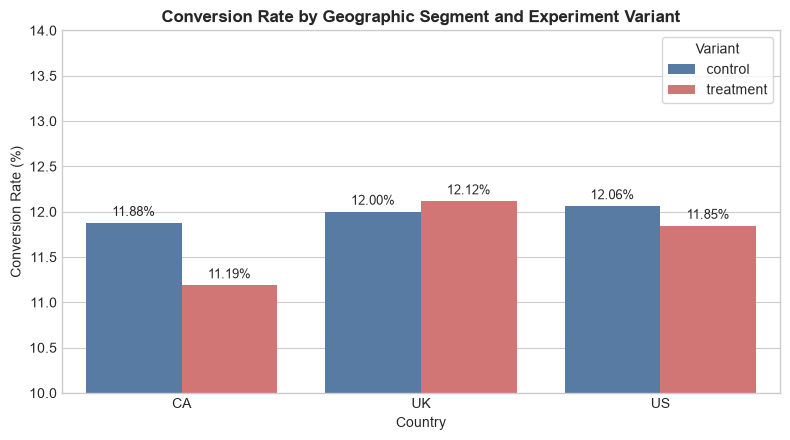

In [11]:
# Aggregate CR by country and group for visualization
plot_df = (
    merged_df.groupby(["country", "group"])["converted"]
    .mean()
    .mul(100)
    .reset_index(name="conversion_rate_pct")
)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(
    data=plot_df,
    x="country",
    y="conversion_rate_pct",
    hue="group",
    palette=["#4a7bb0", "#e06666"],
    ax=ax
)

ax.set_title("Conversion Rate by Geographic Segment and Experiment Variant", fontsize=12, fontweight="bold")
ax.set_ylabel("Conversion Rate (%)", fontsize=10)
ax.set_xlabel("Country", fontsize=10)
ax.set_ylim(10, 14)
ax.legend(title="Variant", frameon=True)

# Add value labels on bars
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width() / 2., h),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9)

plt.tight_layout()
plt.show()

In [12]:
print("=" * 80)
print("FINAL PRODUCT EXPERIMENTATION DECISION & ROLLOUT GOVERNANCE")
print("=" * 80)
print("1. OVERALL LIFT:")
print("   - Difference in conversion rate is not statistically significant (p = 0.1899 >= 0.05).")
print("   - Relative lift trend is flat-to-negative (-0.15% to -1.31%).")
print("\n2. SEGMENTATION & HETEROGENEITY:")
print("   - Independent regional Z-tests show p > 0.05 across all countries (US, UK, CA).")
print("   - Logistic interaction terms show p-values > 0.40, confirming treatment effect does")
print("     not vary across markets (no Simpson's Paradox).")
print("\n3. FINAL DECISION:")
print("   - DO NOT SHIP (Maintain Control).")
print("   - Deploying an ineffective design introduces unnecessary technical debt and")
print("     operational overhead with zero measurable conversion upside.")
print("=" * 80)

FINAL PRODUCT EXPERIMENTATION DECISION & ROLLOUT GOVERNANCE
1. OVERALL LIFT:
   - Difference in conversion rate is not statistically significant (p = 0.1899 >= 0.05).
   - Relative lift trend is flat-to-negative (-0.15% to -1.31%).

2. SEGMENTATION & HETEROGENEITY:
   - Independent regional Z-tests show p > 0.05 across all countries (US, UK, CA).
   - Logistic interaction terms show p-values > 0.40, confirming treatment effect does
     not vary across markets (no Simpson's Paradox).

3. FINAL DECISION:
   - DO NOT SHIP (Maintain Control).
   - Deploying an ineffective design introduces unnecessary technical debt and
     operational overhead with zero measurable conversion upside.
